# 4. Delivery performance and customer satisfaction
Does shipping speed change how customers rate their order?

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [2]:
import json
s = json.loads((OUT / "summary.json").read_text())
print(f"Average delivery time: {s['avg_delivery_days']:.1f} days")
print(f"Delivered late (after the estimated date): {s['late_rate']:.1%}")

Average delivery time: 12.5 days
Delivered late (after the estimated date): 8.1%


## Late vs on-time deliveries

In [3]:
d = pd.read_csv(OUT / "delivery_vs_review.csv")
d["delivery"] = d["is_late"].map({False: "On time", True: "Late"})
d[["delivery", "orders", "avg_review", "low_score_share"]]

,delivery,orders,avg_review,low_score_share
0,On time,88381,4.28,0.09
1,Late,7822,2.55,0.55


On-time orders average **4.28** stars with 9% rating 1 or 2. Late orders average **2.55** stars with 55% rating 1 or 2. Being late is the strongest driver of a bad review in this data.

,delay_bucket,orders,avg_review
0,10+ days early,56944,4.31
1,0 to 10 days early,31432,4.23
2,0 to 3 days late,2660,3.75
3,3 to 7 days late,1819,2.30
4,7+ days late,3343,1.72


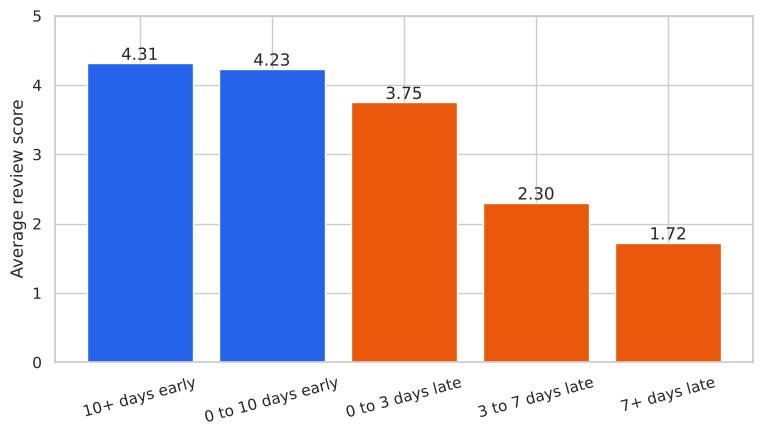

In [4]:
b = pd.read_csv(OUT / "delay_bucket_vs_review.csv")
plt.figure(figsize=(9, 4.5))
bars = plt.bar(b["delay_bucket"], b["avg_review"], color=["#2563eb", "#2563eb", "#ea580c", "#ea580c", "#ea580c"])
for bar, v in zip(bars, b["avg_review"]): plt.text(bar.get_x() + bar.get_width() / 2, v + 0.05, f"{v:.2f}", ha="center")
plt.ylim(0, 5); plt.ylabel("Average review score"); plt.xticks(rotation=15);
b

Even 0 to 3 days late costs half a star, and more than a week late drops the score to 1.7. Delivering early barely helps (4.31 vs 4.23), so the goal is to avoid lateness, not to be as fast as possible.

## Geography
São Paulo (SP) is 38% of revenue and delivers fastest. Other regions wait much longer.

In [5]:
st = pd.read_csv(OUT / "state_performance.csv")
st[st["orders"] >= 500].head(12)[["customer_state", "orders", "revenue_share", "avg_delivery_days", "late_rate", "avg_review"]]

,customer_state,orders,revenue_share,avg_delivery_days,late_rate,avg_review
0,SP,41022,0.38,8.74,0.06,4.20
1,RJ,12655,0.13,15.30,0.13,3.88
2,MG,11457,0.12,11.98,0.06,4.15
3,RS,5396,0.05,15.29,0.07,4.15
4,PR,4963,0.05,11.97,0.05,4.20
5,SC,3590,0.04,14.95,0.10,4.08
6,BA,3340,0.04,19.33,0.14,3.86
7,DF,2115,0.02,12.94,0.07,4.08
8,GO,1990,0.02,15.61,0.08,4.05
9,ES,2014,0.02,15.78,0.12,4.02


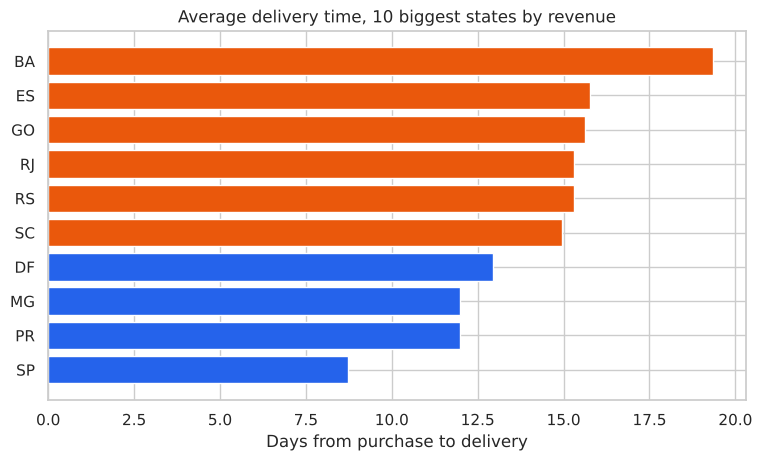

In [6]:
top = st.head(10).sort_values("avg_delivery_days")
plt.figure(figsize=(9, 4.8)); plt.barh(top["customer_state"], top["avg_delivery_days"], color=["#ea580c" if v > 14 else "#2563eb" for v in top["avg_delivery_days"]])
plt.xlabel("Days from purchase to delivery"); plt.title("Average delivery time, 10 biggest states by revenue");

Rio de Janeiro is the second biggest market (13% of revenue) but takes about 15 days versus under 9 in São Paulo, and 13% of its orders arrive late, more than double São Paulo's rate. Bahia and Ceará are worse still, with 19 to 21 day averages.

## Recommendations
1. Put realistic delivery estimates in front of customers in slow regions, so fewer orders count as late.
2. Prioritise carrier and fulfilment fixes for Rio de Janeiro first, because of its size.
3. Flag orders that are about to miss their date and contact the customer before the review is written.
4. Run a second-purchase offer for high-value one-time buyers, since almost nobody returns on their own.